# THAI-EXP-005 — LR regularization

Ngày 18/11/2026.

## Mục tiêu
Kiểm tra regularization mạnh hơn có giúp LR tổng quát hóa sang người mới hay không.
Đối chứng là THAI-EXP-002, LR đủ 68 đặc trưng với C=1.

## Giả thuyết trước khi chạy
C nhỏ hơn có thể giảm điểm train và cải thiện điểm test, nhưng cũng có thể gây underfitting.
Không mặc định rằng điểm số sẽ tăng.

## Thiết lập
- Binary và multiclass; physiological68; seed=42; không cân bằng lớp.
- Giữ nguyên imputer median, StandardScaler, solver và max_iter của LR baseline.
- Chỉ khảo sát C trong [0.001, 0.01, 0.1, 1.0].
- Chọn C bằng Macro-F1 trên inner GroupKFold 3 phần trong outer train.
- Outer LOSO 15 người; R01 kiểm tra S2, R02 giữ nguyên thiết kế và chạy đủ 15 người.
- Đây là nghiên cứu mở rộng sau khi đã quan sát kết quả test trước đó.


In [1]:
from pathlib import Path
from copy import deepcopy, copy
from datetime import datetime
from zoneinfo import ZoneInfo
from time import perf_counter
import os
import sys
import json
import hashlib
import shutil
import warnings

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src/wesad/models.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Không tìm thấy thư mục dự án.")
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("MPLCONFIGDIR", str(Path(os.environ["TEMP"]) / "wesad_matplotlib"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Image
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.metrics import f1_score, balanced_accuracy_score, make_scorer
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from threadpoolctl import threadpool_limits
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from wesad.data import SUBJECTS, load_feature_table
from wesad.evaluation import task_target
from wesad.utils import read_config, file_hash, fingerprint, environment, write_json, provenance

plt.switch_backend("Agg")
NOTEBOOK = ROOT / "notebooks/experiments/Thai_EXP-005_working.ipynb"
ARCHIVE = ROOT / "experiments/04_additional/THAI-EXP-005_LR_Regularization"
REFERENCE_DIR = ROOT / "outputs/notebook_research/THAI-EXP-002/r02_main"
print("Project:", ROOT)
print("Python:", sys.executable)


Project: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection
Python: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\.venv\Scripts\python.exe


## Kiểm tra dữ liệu và đối chứng

In [2]:
defaults = read_config(ROOT / "configs/defaults.yaml")
FEATURES = ROOT / defaults["features"]
SCHEMA = ROOT / defaults["schema"]
assert file_hash(FEATURES) == defaults["feature_sha256"]
df, feature_columns = load_feature_table(FEATURES, SCHEMA, SUBJECTS)
assert len(df) == 6189 and len(feature_columns) == 68
reference_manifest = json.loads((REFERENCE_DIR / "config.json").read_text(encoding="utf-8"))
assert reference_manifest["data_sha256"] == file_hash(FEATURES)
assert reference_manifest["environment"] == environment()
assert reference_manifest["settings"]["balance"] is False
shared_paths = reference_manifest["settings"]["source_paths"]
shared_hash = fingerprint({path: hashlib.sha256((ROOT / path).read_bytes().replace(b"\r\n", b"\n")).hexdigest()
                           for path in shared_paths})
assert shared_hash == reference_manifest["code_sha256"]
print("PASS: checksum, 68 đặc trưng, 15 người và môi trường khớp đối chứng.")
display(pd.crosstab(df.subject_id, df.label_original).reindex(SUBJECTS))


PASS: checksum, 68 đặc trưng, 15 người và môi trường khớp đối chứng.


label_original,1,2,3
subject_id,,,
S2,219,113,63
S3,218,118,65
S4,222,117,65
S5,230,119,65
S6,226,121,65
S7,228,118,65
S8,224,124,64
S9,227,119,65
S10,226,135,65


## Pipeline và đánh giá nested LOSO

In [3]:
def regularized_pipeline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(**reference_manifest["settings"]["model_params"]["lr"])),
    ])

def make_config(run_no, scope):
    return {
        "experiment_id": "THAI-EXP-005", "group_experiment_id": None,
        "run_no": run_no, "run_scope": scope,
        "features": defaults["features"], "schema": defaults["schema"],
        "feature_sha256": defaults["feature_sha256"], "feature_version": defaults["feature_version"],
        "models": ["lr"], "tasks": ["multiclass", "binary"],
        "expected_subjects": list(SUBJECTS), "seed": 42,
        "balance": False, "normalization": "global_train",
        "model_params": deepcopy(reference_manifest["settings"]["model_params"]),
        "selector": None, "C_candidates": [0.001, 0.01, 0.1, 1.0],
        "nested": True, "inner_splits": 3, "scoring": "macro_f1",
        "reference_run": REFERENCE_DIR.relative_to(ROOT).as_posix(),
        "output_dir": f"outputs/notebook_research/THAI-EXP-005/{run_no}_{scope}",
    }

def run_regularization(config, subjects=None):
    code_cells = json.loads(NOTEBOOK.read_text(encoding="utf-8"))["cells"]
    notebook_hash = fingerprint(["".join(c["source"]) for c in code_cells if c["cell_type"] == "code"])
    identity = {"settings": config, "data_sha256": file_hash(FEATURES),
                "feature_columns": feature_columns, "shared_code_sha256": shared_hash,
                "notebook_code_sha256": notebook_hash, "environment": environment()}
    signature = fingerprint(identity)
    out = ROOT / config["output_dir"]
    out.mkdir(parents=True, exist_ok=True)
    manifest_path = out / "config.json"
    if manifest_path.exists():
        assert json.loads(manifest_path.read_text())["signature"] == signature, "Cấu hình đổi: dùng lượt chạy mới."
    write_json(manifest_path, {**provenance(), **identity, "signature": signature})
    write_json(out / "environment.json", environment())
    (out / "config.yaml").write_text(yaml.safe_dump(config, allow_unicode=True, sort_keys=False), encoding="utf-8")
    selected_subjects = list(subjects) if subjects is not None else list(SUBJECTS)
    assert selected_subjects and set(selected_subjects).issubset(SUBJECTS)
    write_json(out / "run_status.json", {"status": "running"})
    X = df[feature_columns].astype(float)
    groups = df.subject_id
    try:
        for task in config["tasks"]:
            y, labels = task_target(df, task)
            for subject in selected_subjects:
                folder = out / "folds" / task / "lr" / subject
                folder.mkdir(parents=True, exist_ok=True)
                done = folder / "complete.json"
                if done.exists():
                    receipt = json.loads(done.read_text())
                    if receipt["signature"] == signature and all((folder / name).is_file() and file_hash(folder / name) == h
                                                                 for name, h in receipt["files"].items()):
                        print(f"{task}/lr/{subject}: SKIP verified", flush=True)
                        continue
                train = np.flatnonzero(groups.ne(subject))
                test = np.flatnonzero(groups.eq(subject))
                assert len(test) and set(groups.iloc[train]).isdisjoint(groups.iloc[test])
                assert groups.iloc[train].nunique() == 14
                X_train, y_train = X.iloc[train], y.iloc[train]
                inner_groups = groups.iloc[train]
                splits = list(GroupKFold(n_splits=3).split(X_train, y_train, inner_groups))
                inner_description = []
                for a, b in splits:
                    ga, gb = set(inner_groups.iloc[a]), set(inner_groups.iloc[b])
                    assert ga.isdisjoint(gb) and subject not in ga | gb
                    inner_description.append({"train_subjects": sorted(ga), "validation_subjects": sorted(gb)})
                started = perf_counter()
                with warnings.catch_warnings(record=True) as caught, threadpool_limits(limits=1):
                    warnings.simplefilter("always")
                    search = GridSearchCV(regularized_pipeline(), {"model__C": config["C_candidates"]},
                                          cv=splits, scoring=make_scorer(f1_score, average="macro", labels=labels, zero_division=0),
                                          n_jobs=1, refit=True, error_score="raise", return_train_score=False)
                    search.fit(X_train, y_train)
                    predicted = search.predict(X.iloc[test])
                chosen = list(feature_columns)
                selected_C = float(search.best_params_["model__C"])
                assert selected_C in config["C_candidates"]
                prediction = df.iloc[test][["subject_id", "window_id"]].copy()
                prediction["task"], prediction["model"] = task, "lr"
                prediction["y_true"], prediction["y_pred"] = y.iloc[test].to_numpy(), predicted
                metric = {"subject_id": subject, "task": task, "model": "lr", "n_test": len(test),
                          "macro_f1": float(f1_score(y.iloc[test], predicted, labels=labels, average="macro", zero_division=0)),
                          "balanced_accuracy": float(balanced_accuracy_score(y.iloc[test], predicted)),
                          "selected_C": selected_C, "inner_macro_f1": float(search.best_score_),
                          "seconds": round(perf_counter() - started, 4)}
                details = {"outer_train_subjects": sorted(set(groups.iloc[train])), "outer_test_subjects": [subject],
                           "inner_splits": inner_description, "best_params": {"model__C": selected_C},
                           "selected_features": chosen, "warnings": sorted(set(str(w.message) for w in caught)),
                           "labels": labels, "confusion_matrix": confusion_matrix(y.iloc[test], predicted, labels=labels).tolist()}
                prediction.to_csv(folder / "predictions.csv", index=False)
                pd.DataFrame(search.cv_results_).to_csv(folder / "inner_cv.csv", index=False)
                write_json(folder / "metrics.json", metric)
                write_json(folder / "details.json", details)
                files = ["predictions.csv", "inner_cv.csv", "metrics.json", "details.json"]
                write_json(done, {"signature": signature, "files": {f: file_hash(folder / f) for f in files}})
                print(f"{task}/lr/{subject}: C={selected_C}; F1={metric['macro_f1']:.4f}", flush=True)
        records, predictions, fold_details, warning_rows = [], [], {}, []
        for task in config["tasks"]:
            for subject in selected_subjects:
                folder = out / "folds" / task / "lr" / subject
                records.append(json.loads((folder / "metrics.json").read_text()))
                predictions.append(pd.read_csv(folder / "predictions.csv"))
                detail = json.loads((folder / "details.json").read_text())
                fold_details[f"{task}/lr/{subject}"] = detail
                warning_rows.extend({"task": task, "subject_id": subject, "warning": w} for w in detail["warnings"])
        metrics = pd.DataFrame(records)
        metrics.to_csv(out / "metrics_by_subject.csv", index=False)
        pd.concat(predictions, ignore_index=True).to_csv(out / "predictions.csv", index=False)
        pd.DataFrame(warning_rows, columns=["task", "subject_id", "warning"]).to_csv(out / "warnings.csv", index=False)
        write_json(out / "splits.json", {key: {k: val[k] for k in ["outer_train_subjects", "outer_test_subjects", "inner_splits"]}
                                          for key, val in fold_details.items()})
        write_json(out / "selected_features.json", {key: val["selected_features"] for key, val in fold_details.items()})
        status = "complete" if set(selected_subjects) == set(SUBJECTS) else "partial"
        results = []
        for task, part in metrics.groupby("task"):
            result = {"task": task, "model": "lr", "n_subjects": len(part)}
            for name in ["macro_f1", "balanced_accuracy"]:
                result[name + "_mean"] = float(part[name].mean())
                result[name + "_std"] = float(part[name].std()) if len(part) > 1 else None
            results.append(result)
        write_json(out / "summary.json", {"status": status, "n_completed_folds": len(metrics), "results": results})
        write_json(out / "run_status.json", {"status": status, "n_completed_folds": len(metrics)})
        return out, metrics
    except Exception as error:
        write_json(out / "run_status.json", {"status": "failed", "error": repr(error)})
        raise

display(regularized_pipeline())


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"keep_empty_features keep_empty_features: bool, default=FalseIf True, features that consist exclusively of missing values when`fit` is called are returned in results when `transform` is called.The imputed value is always `0` except when `strategy=""constant""`in which case `fill_value` will be used instead... versionadded:: 1.2",True
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will al

## R01 — Kiểm tra S2

In [4]:
CONFIG = make_config("r01", "quick")
RUN_DIR, metrics = run_regularization(CONFIG, subjects=["S2"])
assert len(metrics) == 2
display(metrics)
display(pd.read_csv(RUN_DIR / "warnings.csv"))


multiclass/lr/S2: C=0.01; F1=0.4123
binary/lr/S2: C=0.001; F1=0.4148


,subject_id,task,model,n_test,macro_f1,balanced_accuracy,selected_C,inner_macro_f1,seconds
0,S2,multiclass,lr,395,0.412257,0.531449,0.010,0.689177,0.8428
1,S2,binary,lr,395,0.414815,0.496454,0.001,0.900028,0.8711


,task,subject_id,warning


## R02 — LOSO đủ 15 người

Giữ nguyên grid và pipeline của R01, không điều chỉnh theo điểm test S2.

In [5]:
CONFIG_R02 = make_config("r02", "main")
RUN_DIR_R02, metrics_r02 = run_regularization(CONFIG_R02)
assert len(metrics_r02) == 30
assert not metrics_r02.duplicated(["task", "model", "subject_id"]).any()
for task in ["binary", "multiclass"]:
    assert set(metrics_r02.loc[metrics_r02.task.eq(task), "subject_id"]) == set(SUBJECTS)
display(metrics_r02)
summary_r02 = metrics_r02.groupby("task")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
display(summary_r02)
display(pd.read_csv(RUN_DIR_R02 / "warnings.csv"))


multiclass/lr/S2: C=0.01; F1=0.4123
multiclass/lr/S3: C=0.01; F1=0.8159
multiclass/lr/S4: C=0.1; F1=0.7018
multiclass/lr/S5: C=0.001; F1=0.7568
multiclass/lr/S6: C=0.01; F1=0.7585
multiclass/lr/S7: C=0.01; F1=0.6334
multiclass/lr/S8: C=0.001; F1=0.6085
multiclass/lr/S9: C=0.001; F1=0.4796
multiclass/lr/S10: C=0.01; F1=0.5652
multiclass/lr/S11: C=0.001; F1=0.7821
multiclass/lr/S13: C=0.01; F1=0.5791
multiclass/lr/S14: C=0.01; F1=0.6680
multiclass/lr/S15: C=0.01; F1=0.7403
multiclass/lr/S16: C=0.01; F1=0.4231
multiclass/lr/S17: C=0.01; F1=0.6084
binary/lr/S2: C=0.001; F1=0.4148
binary/lr/S3: C=0.001; F1=0.8208
binary/lr/S4: C=0.01; F1=1.0000
binary/lr/S5: C=0.01; F1=0.9277
binary/lr/S6: C=0.001; F1=0.9882
binary/lr/S7: C=0.001; F1=0.9682
binary/lr/S8: C=0.01; F1=0.9551
binary/lr/S9: C=0.001; F1=0.5577
binary/lr/S10: C=0.001; F1=0.9374
binary/lr/S11: C=0.001; F1=0.9972
binary/lr/S13: C=0.001; F1=0.5827
binary/lr/S14: C=0.001; F1=0.9680
binary/lr/S15: C=0.001; F1=0.7811
binary/lr/S16: C=0.

,subject_id,task,model,n_test,macro_f1,balanced_accuracy,selected_C,inner_macro_f1,seconds
0,S2,multiclass,lr,395,0.412257,0.531449,0.010,0.689177,0.9216
1,S3,multiclass,lr,401,0.815895,0.775663,0.010,0.676713,0.9102
2,S4,multiclass,lr,404,0.701802,0.707692,0.100,0.696525,1.0909
3,S5,multiclass,lr,414,0.756783,0.748829,0.001,0.687840,1.0403
4,S6,multiclass,lr,412,0.758466,0.743590,0.010,0.653471,0.9957
5,S7,multiclass,lr,411,0.633430,0.779240,0.010,0.686020,1.1366
6,S8,multiclass,lr,412,0.608514,0.642473,0.001,0.656128,0.8679
7,S9,multiclass,lr,411,0.479581,0.481793,0.001,0.644619,0.9914
8,S10,multiclass,lr,426,0.565212,0.582596,0.010,0.647013,1.2695
9,S11,multiclass,lr,417,0.782119,0.773105,0.001,0.605276,0.8633


macro_f1           balanced_accuracy          
                mean       std              mean       std
task                                                      
binary      0.843009  0.183210          0.856416  0.159658
multiclass  0.635532  0.127945          0.665723  0.113791

,task,subject_id,warning


## So sánh với LR đủ 68 đặc trưng

In [6]:
reference_metrics = pd.read_csv(REFERENCE_DIR / "metrics_by_subject.csv")
comparison = metrics_r02.merge(reference_metrics, on=["task", "subject_id"],
                              suffixes=("_selected", "_reference"), validate="one_to_one")
assert len(comparison) == 30 and comparison.n_test_selected.eq(comparison.n_test_reference).all()
reference_predictions = pd.read_csv(REFERENCE_DIR / "predictions.csv")
current_predictions = pd.read_csv(RUN_DIR_R02 / "predictions.csv")
paired = current_predictions.merge(reference_predictions, on=["task", "subject_id", "window_id"],
                                   suffixes=("_current", "_reference"), validate="one_to_one")
assert len(paired) == 2 * len(df) and paired.y_true_current.eq(paired.y_true_reference).all()
for metric in ["macro_f1", "balanced_accuracy"]:
    comparison[metric + "_delta"] = comparison[metric + "_selected"] - comparison[metric + "_reference"]
display(comparison)
display(comparison.groupby("task")[["macro_f1_delta", "balanced_accuracy_delta"]].agg(["mean", "std"]))
comparison.to_csv(RUN_DIR_R02 / "comparison_by_subject.csv", index=False)


,subject_id,task,model_selected,n_test_selected,macro_f1_selected,balanced_accuracy_selected,selected_C,inner_macro_f1,seconds_selected,model_reference,n_test_reference,macro_f1_reference,balanced_accuracy_reference,seconds_reference,macro_f1_delta,balanced_accuracy_delta
0,S2,multiclass,lr,395,0.412257,0.531449,0.010,0.689177,0.9216,lr,395,0.466127,0.621005,0.6737,-0.053870,-0.089556
1,S3,multiclass,lr,401,0.815895,0.775663,0.010,0.676713,0.9102,lr,401,0.661182,0.622287,0.5461,0.154713,0.153376
2,S4,multiclass,lr,404,0.701802,0.707692,0.100,0.696525,1.0909,lr,404,0.701802,0.707692,0.6586,0.000000,0.000000
3,S5,multiclass,lr,414,0.756783,0.748829,0.001,0.687840,1.0403,lr,414,0.796091,0.852285,0.6578,-0.039308,-0.103456
4,S6,multiclass,lr,412,0.758466,0.743590,0.010,0.653471,0.9957,lr,412,0.786670,0.764103,0.5914,-0.028204,-0.020513
5,S7,multiclass,lr,411,0.633430,0.779240,0.010,0.686020,1.1366,lr,411,0.646601,0.779240,0.5351,-0.013171,0.000000
6,S8,multiclass,lr,412,0.608514,0.642473,0.001,0.656128,0.8679,lr,412,0.473091,0.458789,0.5591,0.135423,0.183684
7,S9,multiclass,lr,411,0.479581,0.481793,0.001,0.644619,0.9914,lr,411,0.664581,0.649300,0.6146,-0.185000,-0.167507
8,S10,multiclass,lr,426,0.565212,0.582596,0.010,0.647013,1.2695,lr,426,0.290313,0.379056,0.5834,0.274899,0.203540
9,S11,multiclass,lr,417,0.782119,0.773105,0.001,0.605276,0.8633,lr,417,0.593778,0.630667,0.8793,0.188341,0.142438


macro_f1_delta           balanced_accuracy_delta          
                     mean       std                    mean       std
task                                                                 
binary           0.032740  0.199771                0.026055  0.160146
multiclass       0.046141  0.121266                0.034252  0.112799

## Biểu đồ kết quả

Ảnh được lưu tại: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\outputs\notebook_research\THAI-EXP-005\r02_main\figures
Cột sai số ở bảng tổng hợp là độ lệch chuẩn giữa các người.
Confusion matrix gộp cửa sổ; bảng tổng hợp tính trung bình theo người.


macro_f1           balanced_accuracy          
                mean       std              mean       std
task                                                      
binary      0.843009  0.183210          0.856416  0.159658
multiclass  0.635532  0.127945          0.665723  0.113791

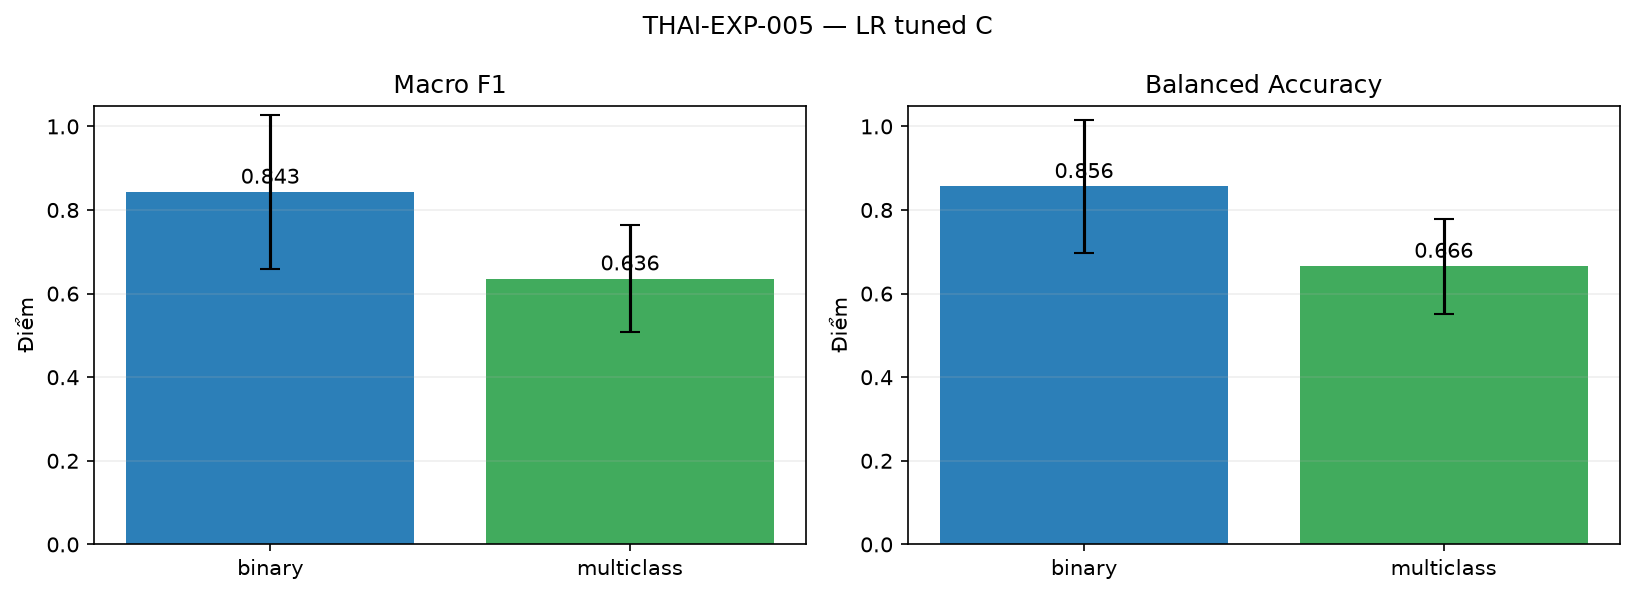

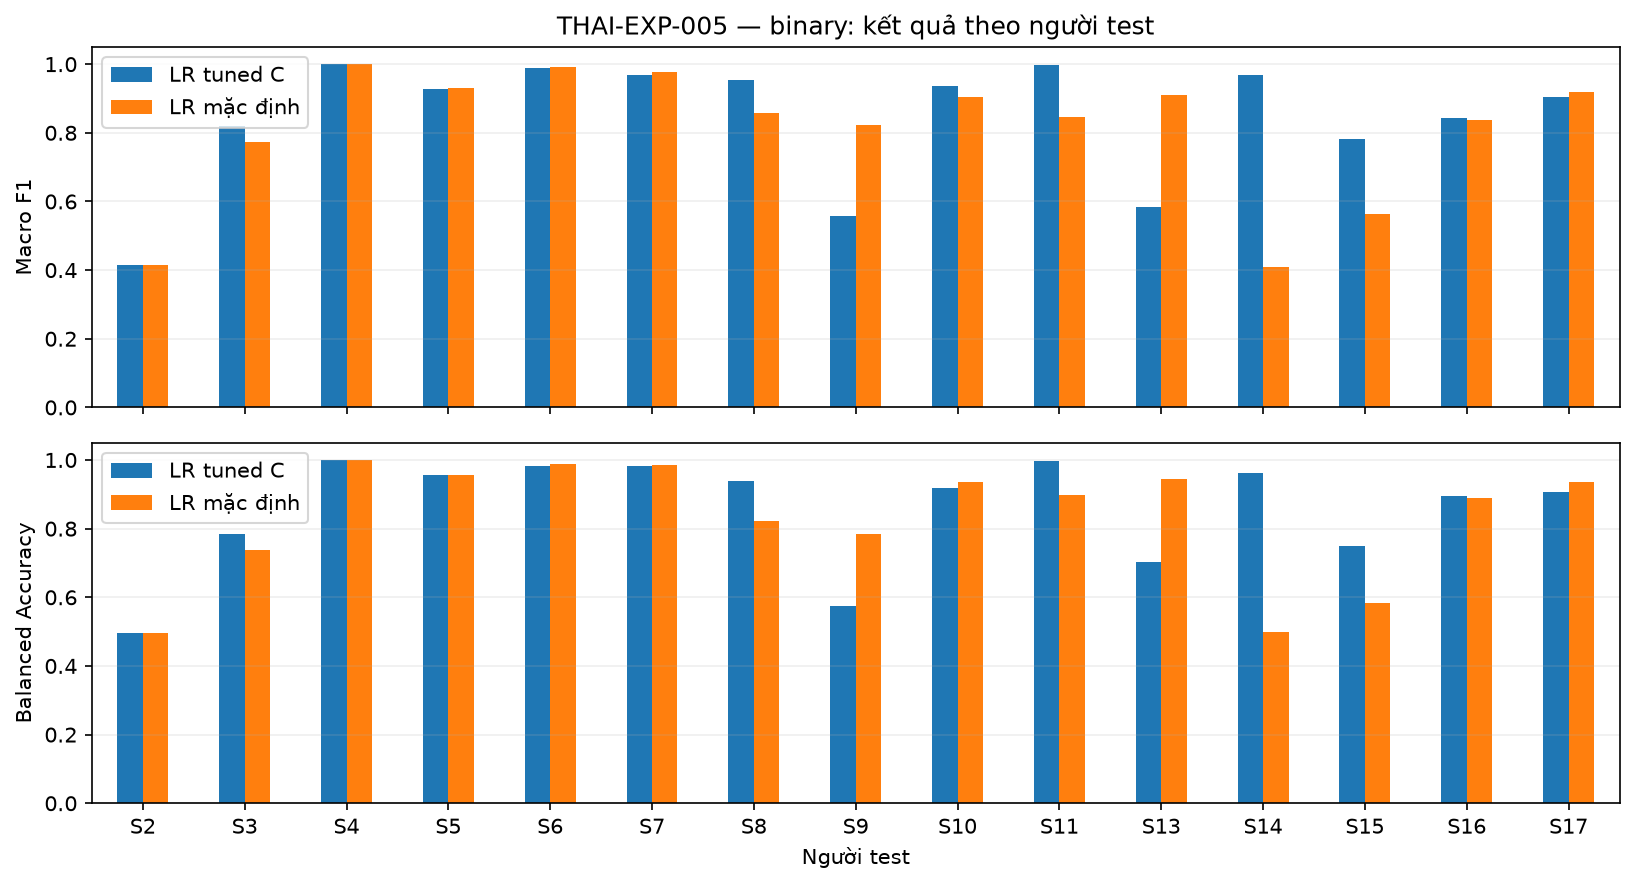

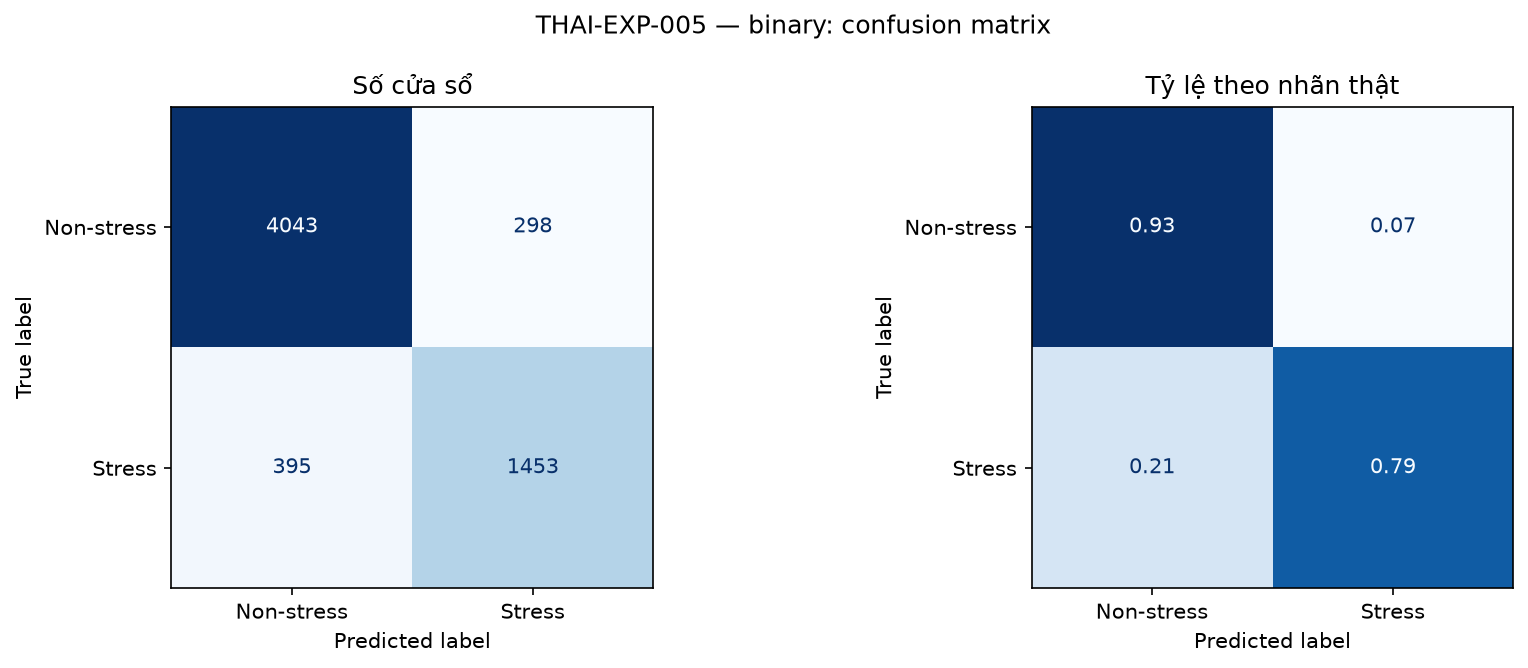

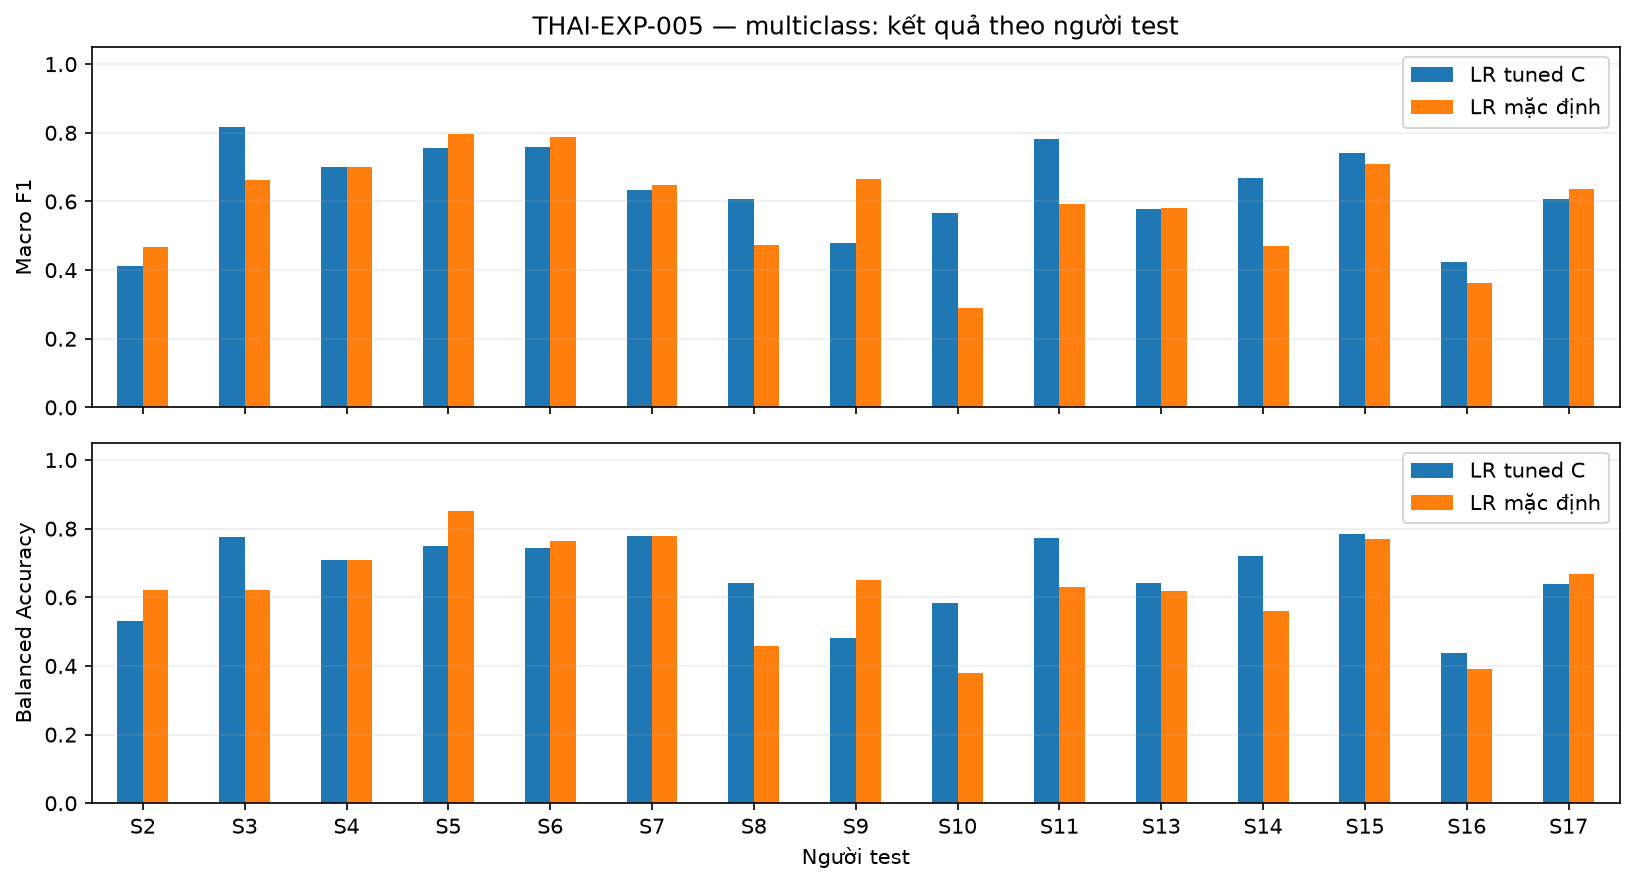

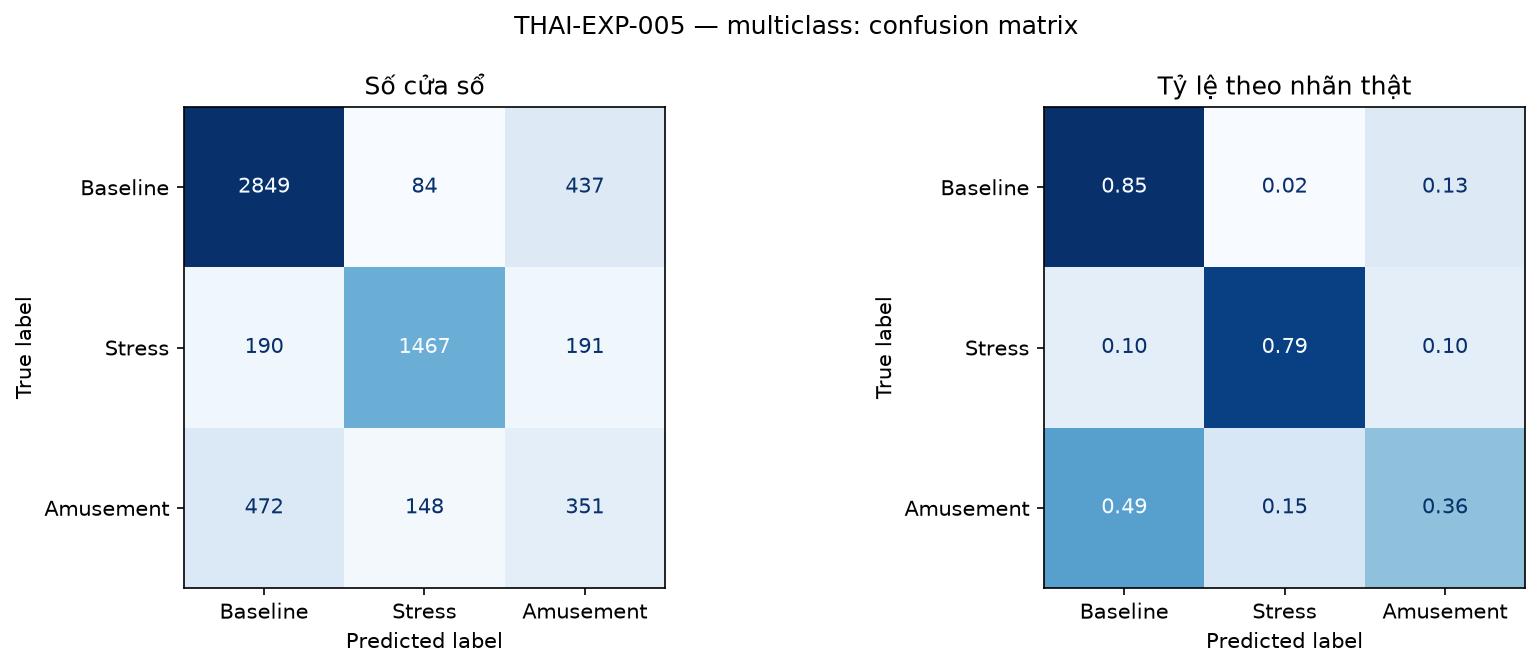

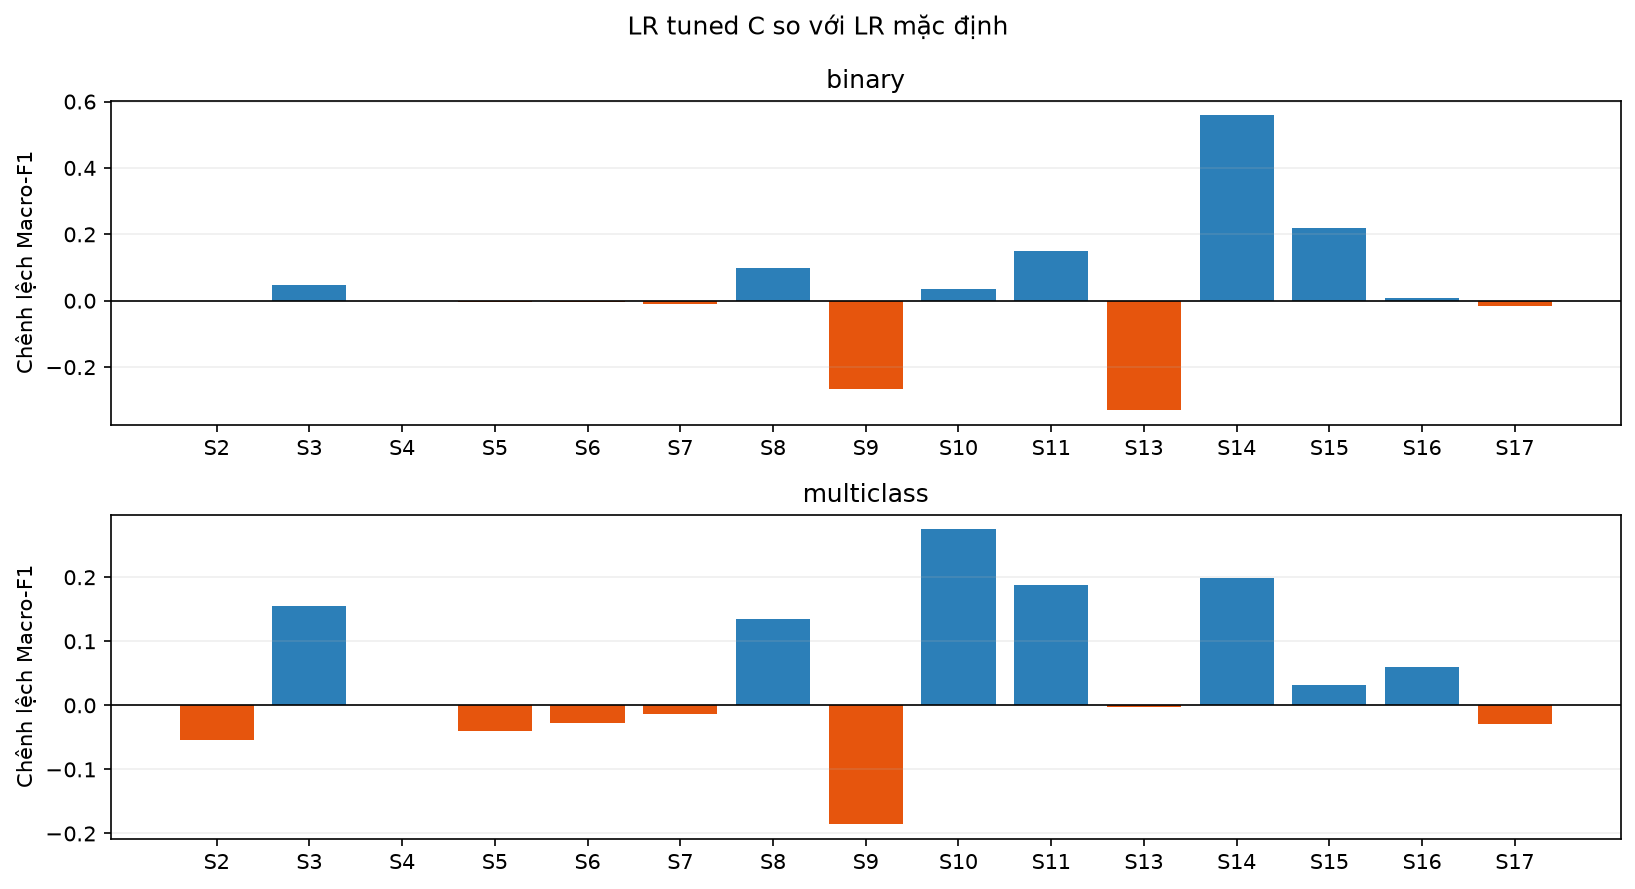

In [7]:
RUN_DIR_VIS = ROOT / "outputs/notebook_research/THAI-EXP-005/r02_main"
REFERENCE_VIS = ROOT / "outputs/notebook_research/THAI-EXP-002/r02_main"
MODEL_LABEL = "LR tuned C"
REFERENCE_LABEL = "LR mặc định"
FIGURES_VIS = RUN_DIR_VIS / "figures"

for name in ["metrics_by_subject.csv", "predictions.csv"]:
    if not (RUN_DIR_VIS / name).is_file():
        raise FileNotFoundError(f"Thiếu kết quả: {RUN_DIR_VIS / name}")

metrics_vis = pd.read_csv(RUN_DIR_VIS / "metrics_by_subject.csv")
predictions_vis = pd.read_csv(RUN_DIR_VIS / "predictions.csv")
assert not metrics_vis.duplicated(["task", "model", "subject_id"]).any()
assert not predictions_vis.duplicated(["task", "model", "subject_id", "window_id"]).any()
assert metrics_vis.model.nunique() == 1
reference_vis = None
if REFERENCE_VIS is not None:
    reference_vis = pd.read_csv(REFERENCE_VIS / "metrics_by_subject.csv")
    paired_vis = metrics_vis.merge(reference_vis, on=["task", "subject_id"],
                                   suffixes=("_current", "_reference"), validate="one_to_one")
    assert len(paired_vis) == len(metrics_vis)
    assert paired_vis.n_test_current.eq(paired_vis.n_test_reference).all()

FIGURES_VIS.mkdir(parents=True, exist_ok=True)
plt.switch_backend("Agg")
def show_figure(fig, filename):
    fig.tight_layout()
    target = FIGURES_VIS / filename
    fig.savefig(target, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(target)))

summary_vis = metrics_vis.groupby("task")[["macro_f1", "balanced_accuracy"]].agg(["mean", "std"])
display(summary_vis)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
    means = summary_vis[(metric, "mean")]
    deviations = summary_vis[(metric, "std")].fillna(0)
    ax.bar(means.index, means, yerr=deviations, capsize=5, color=["#2c7fb8", "#41ab5d"][:len(means)])
    ax.set(title=metric.replace("_", " ").title(), ylim=(0, 1.05), ylabel="Điểm")
    ax.grid(axis="y", alpha=0.2)
    for x, mean in enumerate(means):
        ax.text(x, mean + 0.02, f"{mean:.3f}", ha="center")
fig.suptitle(f"THAI-EXP-005 — {MODEL_LABEL}")
show_figure(fig, "summary_metrics.png")

for task in ["binary", "multiclass"]:
    part = metrics_vis.loc[metrics_vis.task.eq(task)].copy()
    if part.empty:
        continue
    subjects = sorted(part.subject_id.unique(), key=lambda s: int(s[1:]))
    part = part.set_index("subject_id").reindex(subjects)
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    for ax, metric in zip(axes, ["macro_f1", "balanced_accuracy"]):
        scores = pd.DataFrame({MODEL_LABEL: part[metric]})
        if reference_vis is not None:
            ref = reference_vis.loc[reference_vis.task.eq(task)].set_index("subject_id").reindex(subjects)
            scores[REFERENCE_LABEL] = ref[metric]
        scores.plot.bar(ax=ax, ylim=(0, 1.05), rot=0)
        ax.set_ylabel(metric.replace("_", " ").title())
        ax.grid(axis="y", alpha=0.2)
    axes[0].set_title(f"THAI-EXP-005 — {task}: kết quả theo người test")
    axes[1].set_xlabel("Người test")
    show_figure(fig, f"{task}_subject_metrics.png")

    macro_scores = pd.DataFrame({MODEL_LABEL: part["macro_f1"]})
    if reference_vis is not None:
        macro_scores[REFERENCE_LABEL] = ref["macro_f1"]
    ax_macro = macro_scores.plot.bar(figsize=(10, 4), ylim=(0, 1.05), rot=0)
    ax_macro.set(title=f"THAI-EXP-005 — {task}", ylabel="Macro-F1", xlabel="Người test")
    ax_macro.figure.tight_layout()
    ax_macro.figure.savefig(FIGURES_VIS / f"{task}_macro_f1.png", dpi=150)
    plt.close(ax_macro.figure)


    pred = predictions_vis.loc[predictions_vis.task.eq(task)]
    assert len(pred) == int(part.n_test.sum())
    labels = [0, 1] if task == "binary" else [1, 2, 3]
    names = ["Non-stress", "Stress"] if task == "binary" else ["Baseline", "Stress", "Amusement"]
    cm = confusion_matrix(pred.y_true, pred.y_pred, labels=labels)
    row_sums = cm.sum(axis=1, keepdims=True)
    normalized = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    ConfusionMatrixDisplay(cm, display_labels=names).plot(ax=axes[0], cmap="Blues", colorbar=False, values_format="d")
    ConfusionMatrixDisplay(normalized, display_labels=names).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
    axes[0].set_title("Số cửa sổ")
    axes[1].set_title("Tỷ lệ theo nhãn thật")
    fig.suptitle(f"THAI-EXP-005 — {task}: confusion matrix")
    show_figure(fig, f"{task}_confusion_matrix.png")

if reference_vis is not None:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6))
    for ax, task in zip(axes, ["binary", "multiclass"]):
        part = paired_vis.loc[paired_vis.task.eq(task)].copy()
        part["subject_number"] = part.subject_id.str[1:].astype(int)
        part = part.sort_values("subject_number")
        delta = part.macro_f1_current - part.macro_f1_reference
        ax.bar(part.subject_id, delta, color=["#2c7fb8" if d >= 0 else "#e6550d" for d in delta])
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set(title=task, ylabel="Chênh lệch Macro-F1")
        ax.grid(axis="y", alpha=0.2)
    fig.suptitle(f"{MODEL_LABEL} so với {REFERENCE_LABEL}")
    show_figure(fig, "comparison_delta_macro_f1.png")

print("Ảnh được lưu tại:", FIGURES_VIS)
if metrics_vis.subject_id.nunique() == 1:
    print("Lượt kiểm tra một người; chưa dùng để kết luận cho đủ 15 người.")
else:
    print("Cột sai số ở bảng tổng hợp là độ lệch chuẩn giữa các người.")
print("Confusion matrix gộp cửa sổ; bảng tổng hợp tính trung bình theo người.")


## C được chọn trong từng fold

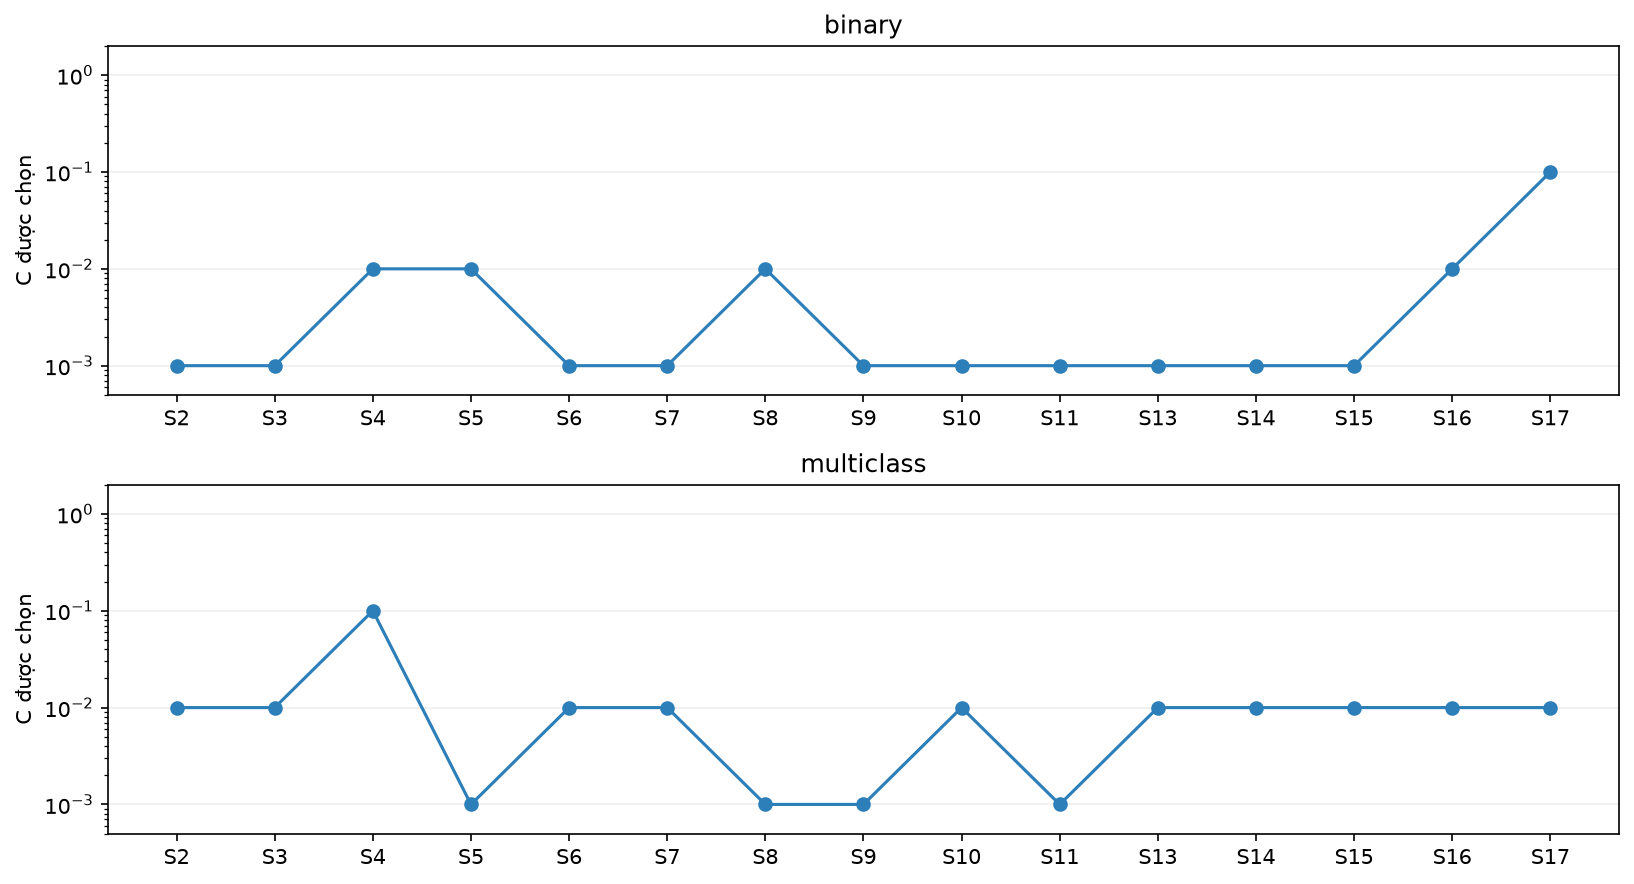

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(11, 6))
for ax, task in zip(axes, ["binary", "multiclass"]):
    part = metrics_r02.loc[metrics_r02.task.eq(task)].set_index("subject_id").reindex(SUBJECTS)
    ax.plot(part.index, part.selected_C, marker="o", color="#2c7fb8")
    ax.set(title=task, ylabel="C được chọn", yscale="log", ylim=(0.0005, 2))
    ax.grid(axis="y", alpha=0.2)
show_figure(fig, "selected_C_by_subject.png")


## Lưu hồ sơ và nhật ký riêng

In [9]:
ARCHIVE.mkdir(parents=True, exist_ok=True)
book = Workbook()
sheet = book.active
sheet.title = "Experiment Log"
sheet.append(["ID", "Ngày / mốc", "Người thực hiện", "Thí nghiệm", "Task", "Models", "Feature set", "Validation",
              "Macro-F1", "Balanced Accuracy", "Nhận xét / trạng thái", "Folder thí nghiệm", "Report", "Config", "Git commit", "EXP chung"])
for run, source, table, config in [("R01", RUN_DIR, metrics, CONFIG), ("R02", RUN_DIR_R02, metrics_r02, CONFIG_R02)]:
    target = ARCHIVE / run.lower()
    target.mkdir(exist_ok=True)
    for filename in ["config.yaml", "config.json", "summary.json", "environment.json", "predictions.csv", "splits.json",
                     "selected_features.json", "warnings.csv", "comparison_by_subject.csv"]:
        if (source / filename).exists(): shutil.copy2(source / filename, target / filename)
    shutil.copy2(source / "metrics_by_subject.csv", target / "results.csv")
    if (source / "figures").exists(): shutil.copytree(source / "figures", target / "figures", dirs_exist_ok=True)
    for task, part in table.groupby("task"):
        suffix = "BIN" if task == "binary" else "MC"
        captured = pd.read_csv(source / "warnings.csv")
        n_warn = len(captured.loc[captured.task.eq(task)])
        note = f"Hoàn tất {len(part)} fold; {n_warn} cảnh báo; C chọn bằng inner GroupKFold."
        if run == "R02":
            sd = part[["macro_f1", "balanced_accuracy"]].std()
            delta = comparison.loc[comparison.task.eq(task), "macro_f1_delta"].mean()
            note += f" SD F1={sd.macro_f1:.6f}; SD BA={sd.balanced_accuracy:.6f}; delta F1={delta:+.6f}."
        sheet.append([f"THAI-EXP-005-{run}-{suffix}", "18/11/2026", None, f"LR regularization — {run}", task, "lr",
                      "physiological68", "Nested LOSO + inner GroupKFold 3 phần", float(part.macro_f1.mean()),
                      float(part.balanced_accuracy.mean()), note, source.relative_to(ROOT).as_posix(),
                      (source / "metrics_by_subject.csv").relative_to(ROOT).as_posix(),
                      "LR đủ 68 đặc trưng; C=0.001/0.01/0.1/1; inner Macro-F1; seed=42; không cân bằng lớp.", None, None])
for c in sheet[1]:
    c.fill = PatternFill("solid", fgColor="17365D")
    c.font = Font(color="FFFFFF", bold=True)
for row in sheet:
    for cell in row: cell.alignment = Alignment(vertical="top", wrap_text=True)
for column in ["A", "B", "D", "H", "K", "L", "M", "N"]: sheet.column_dimensions[column].width = 30
for column in ["I", "J"]:
    sheet.column_dimensions[column].width = 18
    for cell in sheet[column][1:]: cell.number_format = "0.000000"
sheet.freeze_panes = "A2"
sheet.auto_filter.ref = sheet.dimensions
book.save(ARCHIVE / "experiments_logs.xlsx")
print("Đã lưu hồ sơ:", ARCHIVE)


Đã lưu hồ sơ: C:\Users\Home\Desktop\final_ML\DOAN\SGU26_Group09_Machine_Learning\wesad-stress-detection\experiments\04_additional\THAI-EXP-005_LR_Regularization


## Kết quả và nhận xét R02

Đã hoàn thành 30 fold, giữ nguyên thiết kế và grid C đã nêu trước khi chạy.

- binary: Macro-F1 = 0.843009 ± 0.183210; Balanced Accuracy = 0.856416 ± 0.159658.
  So với LR mặc định: delta Macro-F1 = +0.032740; tăng ở 7 người, giảm ở 6 người; gần như bằng ở 2 người.
- multiclass: Macro-F1 = 0.635532 ± 0.127945; Balanced Accuracy = 0.665723 ± 0.113791.
  So với LR mặc định: delta Macro-F1 = +0.046141; tăng ở 7 người, giảm ở 7 người; gần như bằng ở 1 người.

Ghi nhận 0 cảnh báo ở R02. Các C đã chọn theo từng fold được giữ trong best_params và inner_cv.csv.
Kết quả thay đổi giữa các người, vì vậy không chỉ dựa vào điểm trung bình để kết luận.

## Giới hạn

Hướng này được đề xuất sau khi đã xem kết quả outer test của thí nghiệm trước. Đây là phân tích mở rộng/thăm dò, chưa phải kiểm định độc lập mới. Chưa kiểm định thống kê và chưa có tập test ngoài WESAD.

## Quyết định tiếp theo

Giữ nguyên kết quả, tiếp tục THAI-EXP-006 để kiểm tra missing indicator; không sửa grid theo điểm outer test.